In [13]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (Input, Dense, Embedding, Flatten,Concatenate, LSTM)
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [14]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [15]:
symbols = ["AAPL","AIG","BAC","GS","MNST","MSFT","NKE","PFE","PLUG","SHOP","SPCE"]
path = "/content/drive/MyDrive/Βαση Δεδομενων/"

datasets = []

for symbol in symbols:
    df = pd.read_excel(
        f"{path}{symbol}_Data_Technical_Indicators_Combined.xlsx",
        parse_dates=[0]
    )
    df.rename(columns={df.columns[0]: "Date"}, inplace=True)
    df.set_index("Date", inplace=True)
    df = df.sort_index()
    # Δημιουργία Next_Volume
    df["Next_Volume"] = df.iloc[:, 3].shift(-1)
    df["Symbol"] = symbol
    datasets.append(df)

# Κοινές ημερομηνίες για όλες τις μετοχές
common_dates = datasets[0].index
for df in datasets[1:]:
    common_dates = common_dates.intersection(df.index)

# Φιλτράρουμε όλα τα dataframes για τις κοινές ημερομηνίες
for i in range(len(datasets)):
    datasets[i] = datasets[i].loc[common_dates]

# Ενοποίηση όλων των datasets
dataset = pd.concat(datasets, axis=0)
dataset = dataset.dropna()

le = LabelEncoder()
dataset["Symbol_enc"] = le.fit_transform(dataset["Symbol"])
num_symbols = dataset["Symbol_enc"].nunique()

# Features και target
X_volume_num = dataset.iloc[:, [5, 8, 9, 10, 11, 14, 3, 15, 16, 17, 20]]
X_volume_sym = dataset["Symbol_enc"]
y_volume = np.log1p(dataset["Next_Volume"])

In [16]:
print(X_volume_num)
print(X_volume_sym)
print(y_volume)

                RSI     ATR  Real Upper Band  Real Middle Band  \
Date                                                             
2019-01-02  38.1140  1.4110          43.4714           39.1471   
2019-01-03  27.9036  1.5818          42.8920           38.6381   
2019-01-04  35.1259  1.5772          42.4470           38.2987   
2019-01-07  34.9211  1.5146          42.0077           37.9789   
2019-01-08  38.2354  1.4727          41.7450           37.7671   
...             ...     ...              ...               ...   
2024-12-23  41.1601  0.4558           7.3798            6.5970   
2024-12-24  43.2908  0.4432           7.2129            6.5325   
2024-12-26  49.6211  0.4544           7.1512            6.5070   
2024-12-27  47.2697  0.4512           7.0739            6.4745   
2024-12-30  40.3978  0.4590           6.9129            6.4085   

            Real Lower Band      ADX      Close      S&P 500        VIX  \
Date                                                              

In [17]:
# LSTM parameters
TIMESTEPS = 10

def create_sequences(X_volume_num, X_volume_sym, y_volume, timesteps):
    Xn, Xs, yt = [], [], []

    for sym in np.unique(X_volume_sym):
        mask = (X_volume_sym == sym)

        X_volume_sym_df = X_volume_num.loc[mask].reset_index(drop=True)
        y_volume_sym = y_volume.loc[mask].reset_index(drop=True)

        for i in range(timesteps, len(X_volume_sym_df)):
            Xn.append(X_volume_sym_df.iloc[i-timesteps:i].values)
            Xs.append(sym)
            yt.append(y_volume_sym.iloc[i])

    return np.array(Xn), np.array(Xs), np.array(yt)

In [18]:
test_size = 0.2
total_len = len(common_dates)
test_len = int(total_len * test_size)

train_dates = common_dates[:-test_len]
test_dates  = common_dates[-test_len:]

X_num_train = X_volume_num.loc[X_volume_num.index.isin(train_dates)]
X_sym_train = X_volume_sym.loc[X_volume_sym.index.isin(train_dates)]
y_train = y_volume.loc[y_volume.index.isin(train_dates)]

X_num_test = X_volume_num.loc[X_volume_num.index.isin(test_dates)]
X_sym_test = X_volume_sym.loc[X_volume_sym.index.isin(test_dates)]
y_test = y_volume.loc[y_volume.index.isin(test_dates)]

train_dates_sorted = X_num_train.index.unique().sort_values()
val_len = int(len(train_dates_sorted) * 0.2)

train_dates_final = train_dates_sorted[:-val_len]
val_dates = train_dates_sorted[-val_len:]

X_num_train_final = X_volume_num.loc[X_volume_num.index.isin(train_dates_final)]
X_sym_train_final = X_volume_sym.loc[X_volume_sym.index.isin(train_dates_final)]
y_train_final = y_volume.loc[y_volume.index.isin(train_dates_final)]

X_num_val = X_volume_num.loc[X_volume_num.index.isin(val_dates)]
X_sym_val = X_volume_sym.loc[X_volume_sym.index.isin(val_dates)]
y_val = y_volume.loc[y_volume.index.isin(val_dates)]

In [19]:
# Feature scaling
sc = StandardScaler()
X_num_train_final = sc.fit_transform(X_num_train_final)
X_num_val = sc.transform(X_num_val)
X_num_test = sc.transform(X_num_test)

In [20]:
# Sequences
Xn_train, Xs_train, y_train_seq = create_sequences( pd.DataFrame(X_num_train_final), X_sym_train_final.reset_index(drop=True), y_train_final.reset_index(drop=True), TIMESTEPS )
Xn_val, Xs_val, y_val_seq = create_sequences( pd.DataFrame(X_num_val), X_sym_val.reset_index(drop=True), y_val.reset_index(drop=True), TIMESTEPS )
Xn_test, Xs_test, y_test_seq = create_sequences( pd.DataFrame(X_num_test), X_sym_test.reset_index(drop=True), y_test.reset_index(drop=True), TIMESTEPS )

In [21]:
# Νευρωνικό Δίκτυο
num_input = Input(shape=(TIMESTEPS, Xn_train.shape[2]), name="num_input")
sym_input = Input(shape=(1,), name="sym_input")

sym_embed = Embedding(num_symbols, 4)(sym_input)
sym_embed = Flatten()(sym_embed)

x = LSTM(64)(num_input)
x = Concatenate()([x, sym_embed])
x = Dense(32, activation="relu")(x)
x = Dense(16, activation="relu")(x)
output = Dense(1, activation="linear")(x)
model = Model([num_input, sym_input], output)
model.compile(optimizer=Adam(0.0005), loss="mean_squared_error", metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),tf.keras.metrics.RootMeanSquaredError(name='rmse'),tf.keras.metrics.MeanAbsolutePercentageError(name='mape')])
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True )
history=model.fit([Xn_train, Xs_train],y_train_seq, validation_data=([Xn_val, Xs_val], y_val_seq), epochs=1000, batch_size=16, callbacks=[early_stopping])

Epoch 1/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - loss: 1.4447 - mae: 0.5828 - mape: 15.9120 - rmse: 1.2019 - val_loss: 0.0662 - val_mae: 0.1646 - val_mape: 5.0474 - val_rmse: 0.2574
Epoch 2/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0187 - mae: 0.0914 - mape: 2.7671 - rmse: 0.1367 - val_loss: 0.0594 - val_mae: 0.1500 - val_mape: 4.6578 - val_rmse: 0.2437
Epoch 3/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 0.0090 - mae: 0.0663 - mape: 1.9084 - rmse: 0.0949 - val_loss: 0.0448 - val_mae: 0.1308 - val_mape: 3.9989 - val_rmse: 0.2116
Epoch 4/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0063 - mae: 0.0571 - mape: 1.6016 - rmse: 0.0792 - val_loss: 0.0360 - val_mae: 0.1069 - val_mape: 3.4018 - val_rmse: 0.1897
Epoch 5/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - loss: 0.0049 - mae: 0.0511 - mape: 1.4119 - rmse: 0.0697 - val_loss: 0.0298 - val_mae: 0.0950 - val_mape: 3.0451 - val_rmse: 0.1726
Epoch 6/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - l

In [22]:
test_loss, test_mae , test_rmse, test_mape = model.evaluate([Xn_test,Xs_test], y_test_seq)
print(f"Test Loss (MSE): {test_loss}, Test MAE: {test_mae}")

101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2930 - mae: 0.2563 - mape: 14.9939 - rmse: 0.5413
Test Loss (MSE): 0.2930396795272827, Test MAE: 0.25628626346588135


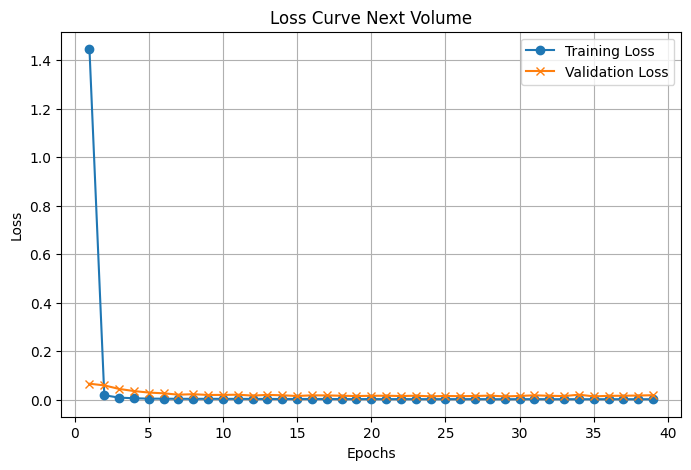

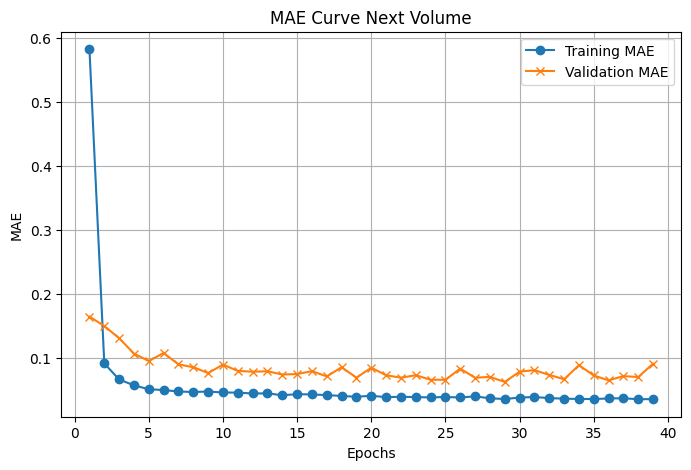

In [23]:
# Γραφικές παραστάσεις
epochs = range(1, len(history.history['loss']) + 1)

# Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss', marker='x')
plt.title('Loss Curve Next Volume')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# MAE Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['mae'], label='Training MAE', marker='o')
plt.plot(epochs, history.history['val_mae'], label='Validation MAE', marker='x')
plt.title('MAE Curve Next Volume')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
y_pred = model.predict([Xn_test,Xs_test])

y_test_real = np.expm1(y_test_seq).reshape(-1)
y_pred_real = np.expm1(y_pred).reshape(-1)


mae  = mean_absolute_error((y_test_real), (y_pred_real))
rmse = np.sqrt(mean_squared_error((y_test_real), (y_pred_real)))
mape = np.mean(np.abs(((y_test_real) - (y_pred_real)) / (y_test_real))) * 100
r2   = r2_score((y_test_real), (y_pred_real))
relative_mae = mae / np.mean(y_test_real) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.3f}")
print(f"Relative MAE: {relative_mae:.2f}%")

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
MAE  : 9.30
RMSE : 14.27
MAPE : 68.13%
R²   : 0.991
Relative MAE: 7.09%
